# Conformer convergence study

metrics vs. number of conformers N, subsampled from one optimized 500 conformer pool.
N=500 is the reference, not ground truth. it only shows convergence relative to this pool

In [ ]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit.Chem import Descriptors3D

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

sys.path.insert(0, str(ROOT.parent))  # .../ensemblelab/src

from ensemblelab import GFN2xTBOptimizer, HierarchicalOptimizer, MMFFOptimizer, generate, RMSDFilter, replace
from ensemblelab.convergence.geometry import analyze_geometry
from ensemblelab.convergence.populations import analyze_populations

In [4]:
MOLECULES = {
    "n-octanol": "CCCCCCCCO",
    "benzoic acid": "OC(=O)c1ccccc1",
    "ibuprofen": "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
    "decanol": "CCCCCCCCCCO",
    "PFOA": "OC(=O)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)F",
}
RUN = ["n-octanol"]  # extend once one molecule works end to end

POOL_SIZE = 500
SAMPLE_SIZES = [5, 10, 25, 50, 100, 250, 500]
N_DRAWS = 10
SEED = 0
TEMPERATURE = 298.15  # K
WINDOW = 3.0  # kcal/mol
OPTIMIZERS = [MMFFOptimizer()] # GFN2xTBOptimizer()

CACHE_DIR = ROOT / "data" / "processed" / "convergence"
RESULTS_DIR = ROOT / "data" / "results"
FIGURES_DIR = ROOT / "data" / "figures"

DESCRIPTORS = ["radius_of_gyration", "asphericity", "eccentricity", "max_distance"]

In [ ]:
def optimized_pool(name, smiles):
    """Generate + optimize POOL_SIZE conformers once; cached as a pickled Ensemble."""
    tag = "_".join(o.method for o in OPTIMIZERS)
    path = CACHE_DIR / f"{name.replace(' ', '_')}_{POOL_SIZE}_{tag}.pkl"
    if path.exists():
        return pickle.loads(path.read_bytes())
    pool = HierarchicalOptimizer(OPTIMIZERS).optimize(generate(smiles, n_confs=POOL_SIZE))
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(pickle.dumps(pool))
    return pool


def conformer_descriptors(pool):
    """Per-conformer energy and shape descriptors for the whole pool, indexed by conformer id."""
    rg = {r["conformer_id"]: r["radius_of_gyration_A"] for r in analyze_geometry(pool)["conformers"]}
    rows = []
    for c in pool.conformers:
        xyz = c.atoms.positions
        rows.append({
            "id": c.id,
            "energy": c.energy,
            "radius_of_gyration": rg[c.id],
            "asphericity": Descriptors3D.Asphericity(pool.molecule, confId=c.id),
            "eccentricity": Descriptors3D.Eccentricity(pool.molecule, confId=c.id),
            "max_distance": np.linalg.norm(xyz[:, None] - xyz[None], axis=-1).max(),
        })
    return pd.DataFrame(rows).set_index("id")


def subset_metrics(pool, desc, subset, e_ref):
    """Boltzmann weights recomputed within the subset (subset E_min), then ensemble metrics."""
    sub = replace(pool, conformers=tuple(subset)) # wrap subset as an ensemble
    subset = list(RMSDFilter().apply(sub).conformers) # deduplicate subset by RMSD
    pops = analyze_populations(pool, TEMPERATURE, conformers=subset)
    p = pd.Series({r["conformer_id"]: r["population"] for r in pops["conformers"]})
    rel = pd.Series({r["conformer_id"]: r["relative_energy"] for r in pops["conformers"]})
    d = desc.loc[p.index]
    out = {m: float((p * d[m]).sum()) for m in DESCRIPTORS}
    out["lowest_energy_rel"] = d["energy"].min() - e_ref
    out["top_population"] = pops["summary"]["max_population"]
    out["n_effective"] = pops["summary"]["effective_ensemble_size"]
    out["n_within_3kcal"] = int((rel <= WINDOW).sum())
    return out


def run_molecule(name, smiles):
    pool = optimized_pool(name, smiles)
    desc = conformer_descriptors(pool)
    e_ref = desc["energy"].min()
    n_pool = len(pool.conformers)
    sizes = [n for n in SAMPLE_SIZES if n < n_pool] + [n_pool]
    rng = np.random.default_rng(SEED)
    rows = []
    for n in sizes:
        for draw in range(1 if n == n_pool else N_DRAWS):
            idx = np.sort(rng.choice(n_pool, size=n, replace=False))
            subset = [pool.conformers[i] for i in idx]
            for metric, value in subset_metrics(pool, desc, subset, e_ref).items():
                rows.append({"molecule": name, "N": n, "draw": draw, "metric": metric, "value": value})
    return pd.DataFrame(rows)

In [9]:
df = pd.concat([run_molecule(name, MOLECULES[name]) for name in RUN], ignore_index=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(RESULTS_DIR / "convergence_study.csv", index=False)
df.head()

,molecule,N,draw,metric,value
0,n-octanol,5,0,radius_of_gyration,2.962062
1,n-octanol,5,0,asphericity,0.675220
2,n-octanol,5,0,eccentricity,0.991226
3,n-octanol,5,0,max_distance,9.199212
4,n-octanol,5,0,lowest_energy_rel,1.827071


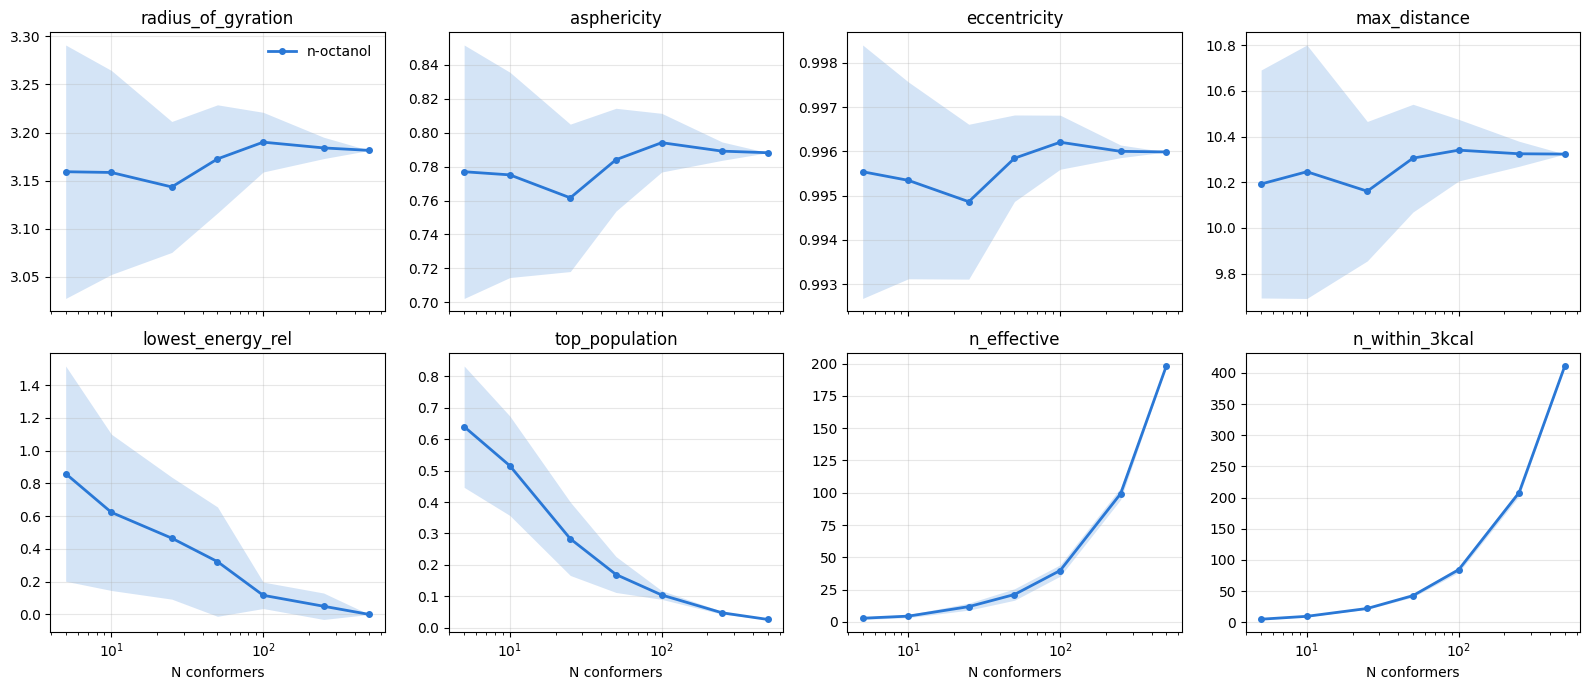

In [10]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # fixed per molecule
MOLECULE_COLOR = dict(zip(MOLECULES, COLORS))
metrics = df["metric"].unique()

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for ax, metric in zip(axes.flat, metrics):
    for name, g in df[df["metric"] == metric].groupby("molecule"):
        s = g.groupby("N")["value"].agg(["mean", "std"]).fillna(0.0)
        color = MOLECULE_COLOR[name]
        ax.plot(s.index, s["mean"], "o-", color=color, lw=2, ms=4, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=color, alpha=0.2, lw=0)
    ax.set_xscale("log")
    ax.set_title(metric)
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("N conformers")
axes.flat[0].legend(frameon=False)
fig.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES_DIR / "convergence_study_metrics.png", dpi=150)

In [ ]:
REL_TOL = 0.01
ABS_TOL = {"lowest_energy_rel": 0.1}  # kcal/mol; reference is ~0, so relative tolerance is meaningless


def convergence_n(means, metric):
    """Smallest N whose mean stays within tolerance of the largest-N value for all larger N."""
    ref = means.iloc[-1]
    tol = ABS_TOL.get(metric, REL_TOL * abs(ref))
    n_conv = means.index[-1]
    for n, value in means.iloc[::-1].items():
        if abs(value - ref) > tol:
            break
        n_conv = n
    return n_conv


means = df.groupby(["molecule", "metric", "N"])["value"].mean()
conv = (
    means.groupby(level=["molecule", "metric"])
    .apply(lambda s: convergence_n(s.droplevel([0, 1]), s.name[1]))
    .unstack("metric")
)
conv

In [ ]:
fig, ax = plt.subplots(figsize=(10, 1 + 0.6 * len(conv)))
im = ax.imshow(np.log10(conv.values.astype(float)), cmap="Blues", vmin=np.log10(5), vmax=np.log10(POOL_SIZE), aspect="auto")
ax.set_xticks(range(conv.shape[1]), conv.columns, rotation=45, ha="right")
ax.set_yticks(range(conv.shape[0]), conv.index)
for i in range(conv.shape[0]):
    for j in range(conv.shape[1]):
        v = conv.iat[i, j]
        ax.text(j, i, int(v), ha="center", va="center", color="white" if v >= 100 else "black")
ax.set_title(f"N to converge (within {REL_TOL:.0%} of N={POOL_SIZE})")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "convergence_study_heatmap.png", dpi=150)